In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))      # the folder above this notebook
import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from utils.config import GameConfig
from utils.models import build_main_model
from utils.utils import make_optimizer, make_training_data
from utils.training import train
from utils.lossFunctions import NMultiMarketCournotLoss
from utils.evaluation import CournotEvaluator
from utils.metrics import merits, cournot_relative_losses

In [2]:
def make_loss_config(M, seed=0,
                     alpha_range=(10.0, 30.0), beta_range=(0.5, 1.5),
                     qbar_range=(20.0, 20.0), lambda_range=(0.5, 2.5),
                     gamma_range=(0.1, 1.0)):
    """Market k's parameters come from a generator seeded by seed + k,
    so a given market is identical regardless of the total number of markets M."""
    alpha_m, beta_m, qbar_m, lambda_m = [], [], [], []
    gammas = [[] for _ in range(3)]
    for k in range(M):
        rng = np.random.default_rng(seed + k)
        alpha_m.append(rng.uniform(*alpha_range))
        beta_m.append(rng.uniform(*beta_range))
        qbar_m.append(rng.uniform(*qbar_range))
        lambda_m.append(rng.uniform(*lambda_range))
        for p in range(3):
            gammas[p].append(rng.uniform(*gamma_range, size=2).round(2).tolist())
    return dict(alpha_m=tuple(alpha_m), beta_m=tuple(beta_m), qbar_m=tuple(qbar_m),
                lambda_m=tuple(lambda_m), Gammas=[np.array(g) for g in gammas])


THETA_LOW  = np.array([[0.5, 1.0], [1.0, 1.5], [1.5, 2.0]], dtype=np.float32)
THETA_HIGH = np.array([[2.0, 3.0], [3.0, 4.0], [4.0, 5.0]], dtype=np.float32)


def make_game_def(M, cfg):
    """M-market Cournot game in the project's game_def format (no UnitNorm)."""
    return {
        "kind": "cournot", "n": 3, "n_players": 3, "z": [M] * 3, "d": [2] * 3,
        "theta_low": THETA_LOW, "theta_high": THETA_HIGH,
        "action_low": np.zeros(3, dtype=np.float32),
        "action_high": np.array([20.0, 20.0, 20.0], dtype=np.float32),
        "loss_func": NMultiMarketCournotLoss(alpha_m=cfg["alpha_m"], beta_m=cfg["beta_m"],
                                             qbar_m=cfg["qbar_m"], lambda_m=cfg["lambda_m"],
                                             Gammas=cfg["Gammas"]),
        "symmetric": False, "dual_output": "softplus", "unit_norm": False,
    }


GAMES = {M: make_game_def(M, make_loss_config(M, seed=10)) for M in range(2, 11)}

In [3]:
STEPS = 100_000
PRINT_EVERY=10000
M_SAMPLES, BATCH = 1000, 500
SGD_ALPHA_0 = 1e-4
REPEATS, BASE_SEED, DATA_SEED = 5, 15, 15
RUN_PREFIX = "scal_v15"          # change it to start fresh: train() resumes runs with an existing name


def run_one(M, game_def, seed):
    """Train one model with the project's train() (SGD schedule from make_optimizer, no L2),
    then evaluate it. Returns training time (s), merit, and pooled relative loss."""
    config = GameConfig(game="cournot", optimizer="sgd", run_n=f"{RUN_PREFIX}_z{M}_s{seed}",
                        seed=seed, max_iters=STEPS, m=M_SAMPLES, batch_size=BATCH,
                        sgd_alpha_0=SGD_ALPHA_0)
    init = tf.keras.initializers.RandomUniform(minval=-0.5, maxval=0.5, seed=seed)
    model = build_main_model(game_def, init, 0.0)
    data = make_training_data(game_def, M_SAMPLES, DATA_SEED)     # same samples for every repeat

    start = time.perf_counter()
    train(model, make_optimizer(config), game_def, config, training_data=data,
          save_weight_every=10**9, print_every=PRINT_EVERY)
    seconds = time.perf_counter() - start

    merit, _ = merits(model, game_def, data)
    _, rel_loss, _ = cournot_relative_losses(CournotEvaluator(model, game_def, seed=seed), seed=seed)
    return seconds, merit, rel_loss

In [ ]:
rows = []
for M, game_def in GAMES.items():
    for r in range(REPEATS):
        seed = BASE_SEED + r
        seconds, merit, rel_loss = run_one(M, game_def, seed)
        rows.append(dict(M=M, seed=seed, time_sec=seconds, merit=merit, relative_loss=rel_loss))
        print(f"z={M}  seed={seed}  time {seconds:.1f}s  merit {merit:.3e}  rel. loss {rel_loss:.3e}")
runs = pd.DataFrame(rows)

No checkpoint found, starting from scratch.
Saved training data to /Users/andresho/Desktop/Continuous-Type-BNE/saved_models/cournot/sgd_scal_v15_z2_s15/training_data.npy
Training steps 1 to 100,000
step 10,000  merit 1.198e+00  176.9 it/s  elapsed 0.02 h  ~0.1 h left
step 20,000  merit 2.644e-01  171.0 it/s  elapsed 0.03 h  ~0.1 h left
step 30,000  merit 1.221e-01  168.1 it/s  elapsed 0.05 h  ~0.1 h left
step 40,000  merit 4.031e-02  180.6 it/s  elapsed 0.06 h  ~0.1 h left
step 50,000  merit 3.763e-02  173.8 it/s  elapsed 0.08 h  ~0.1 h left
step 60,000  merit 1.911e-02  164.6 it/s  elapsed 0.10 h  ~0.1 h left
step 70,000  merit 1.972e-02  183.0 it/s  elapsed 0.11 h  ~0.0 h left
step 80,000  merit 1.651e-02  172.5 it/s  elapsed 0.13 h  ~0.0 h left
step 90,000  merit 1.610e-02  167.7 it/s  elapsed 0.14 h  ~0.0 h left
step 100,000  merit 1.658e-02  174.2 it/s  elapsed 0.16 h  ~0.0 h left
Saved checkpoint at step 100000: /Users/andresho/Desktop/Continuous-Type-BNE/saved_models/cournot/sgd

No checkpoint found, starting from scratch.
Saved training data to /Users/andresho/Desktop/Continuous-Type-BNE/saved_models/cournot/sgd_scal_v15_z2_s16/training_data.npy
Training steps 1 to 100,000
step 10,000  merit 2.186e+00  166.2 it/s  elapsed 0.02 h  ~0.2 h left
step 20,000  merit 3.786e-01  167.1 it/s  elapsed 0.03 h  ~0.1 h left
step 30,000  merit 1.943e-01  167.6 it/s  elapsed 0.05 h  ~0.1 h left
step 40,000  merit 5.510e-02  164.1 it/s  elapsed 0.07 h  ~0.1 h left
step 50,000  merit 2.472e-02  165.2 it/s  elapsed 0.08 h  ~0.1 h left
step 60,000  merit 2.065e-02  171.8 it/s  elapsed 0.10 h  ~0.1 h left
step 70,000  merit 2.438e-02  158.6 it/s  elapsed 0.12 h  ~0.1 h left


    time_mean  time_std  merit_mean  merit_std  rloss_mean  rloss_std
M                                                                    
2       222.5     1.137     0.01552   0.007744   5.624e-06  2.315e-06
3       226.9     3.832      0.1694     0.3168   7.314e-05  0.0001368
4         229     3.683     0.09156    0.07795   2.272e-05  1.602e-05
5       227.4    0.5917      0.1765      0.177   2.952e-05  2.672e-05
6       234.2     3.679       5.867      10.79    0.007617      0.016
7       233.5     1.991      0.5989     0.6579   9.899e-05  0.0001016
8       234.4     1.551      0.9112     0.9781   0.0001775  0.0002139
9       239.5     4.152       1.182       1.42   0.0006025  0.0008028
10      240.5     1.697       4.341      5.528   0.0007061   0.000756

% LaTeX rows
2 & $222.45 \pm 1.14$ & $1.55\times10^{-2} \pm 7.7\times10^{-3}$ & $5.62\times10^{-6} \pm 2.3\times10^{-6}$ \\
3 & $226.88 \pm 3.83$ & $1.69\times10^{-1} \pm 3.2\times10^{-1}$ & $7.31\times10^{-5} \pm 1.4\times10^{-4

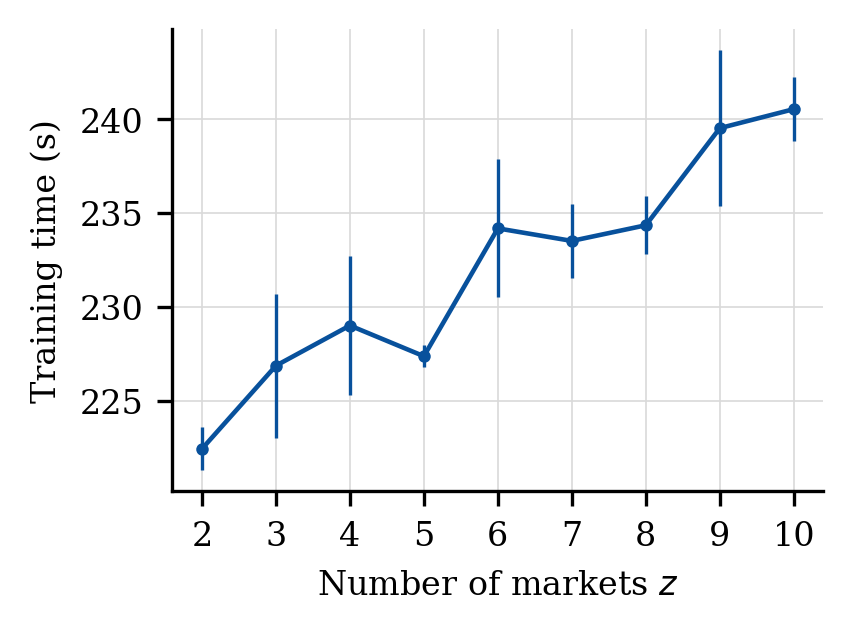

In [7]:
summary = runs.groupby("M").agg(
    time_mean=("time_sec", "mean"), time_std=("time_sec", "std"),
    merit_mean=("merit", "mean"), merit_std=("merit", "std"),
    rloss_mean=("relative_loss", "mean"), rloss_std=("relative_loss", "std"))
print(summary.to_string(float_format=lambda v: f"{v:.4g}"))

def sci(x, digits=2):
    mantissa, exponent = f"{x:.{digits}e}".split("e")
    return rf"{mantissa}\times10^{{{int(exponent)}}}"

print("\n% LaTeX rows")
for M, s in summary.iterrows():
    print(rf"{M} & ${s.time_mean:.2f} \pm {s.time_std:.2f}$ & ${sci(s.merit_mean)} \pm {sci(s.merit_std, 1)}$ "
          rf"& ${sci(s.rloss_mean)} \pm {sci(s.rloss_std, 1)}$ \\")

plt.rcParams.update({'font.family': 'serif', 'font.size': 8, 'axes.spines.top': False,
                     'axes.spines.right': False, 'savefig.dpi': 600})
fig, ax = plt.subplots(figsize=(2.8, 2.0), dpi=300)
ax.errorbar(summary.index, summary.time_mean, yerr=summary.time_std, color='#08519c',
            lw=1.1, elinewidth=0.8, capsize=4, capthick=0.8,
            marker='o', markersize=3, markeredgewidth=0)
ax.set_xlabel('Number of markets $z$')
ax.set_ylabel('Training time (s)')
ax.set_xticks(summary.index)
ax.grid(True, lw=0.4, color='0.85')
ax.set_axisbelow(True)
fig.savefig('images/scalable_graph.png', bbox_inches='tight', pad_inches=0.02)
plt.show()

In [20]:
import tensorflow as tf, platform
print(platform.platform())
print("TF:", tf.__version__)
print("Devices:", tf.config.list_physical_devices())
!lscpu | grep -E "Model name|CPU\(s\):"
!free -h

Linux-5.14.0-611.54.6.el9_7.x86_64-x86_64-with-glibc2.10
TF: 2.13.1
Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
CPU(s):                                  16
Model name:                              AMD EPYC 7313P 16-Core Processor
NUMA node0 CPU(s):                       0-15
               total        used        free      shared  buff/cache   available
Mem:           251Gi        11Gi       188Gi       320Mi        54Gi       240Gi
Swap:             0B          0B          0B


In [9]:
runs.to_csv("scalability_runs_v1.csv", index=False)

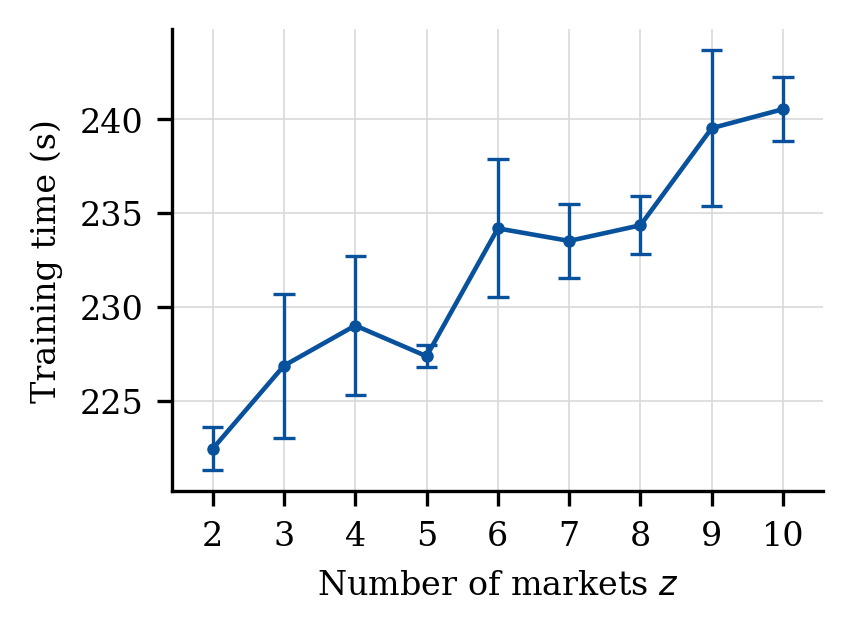

In [10]:
z = np.asarray(summary.index, dtype=float)
mean, std = summary.time_mean.to_numpy(), summary.time_std.to_numpy()
cap = 0.15                                   # half-width of the caps, in x units

fig, ax = plt.subplots(figsize=(2.8, 2.0), dpi=300)
ax.vlines(z, mean - std, mean + std, color='#08519c', lw=0.8, zorder=1)
ax.hlines(mean - std, z - cap, z + cap, color='#08519c', lw=0.8, zorder=1)    # lower caps
ax.hlines(mean + std, z - cap, z + cap, color='#08519c', lw=0.8, zorder=1)    # upper caps
ax.plot(z, mean, color='#08519c', lw=1.1, marker='o', markersize=3,
        markeredgewidth=0, zorder=2)

ax.set_xlabel('Number of markets $z$')
ax.set_ylabel('Training time (s)')
ax.set_xticks(z)
ax.grid(True, lw=0.4, color='0.85')
ax.set_axisbelow(True)
fig.savefig('images/scalable_graph.png', bbox_inches='tight', pad_inches=0.02)
plt.show()